# WQF7009 Assignment 1: Using SHAP for Stroke Prediction Model
## Part 1: EDA

Author: Gan Yee Jing (25102061)

Creation Date: 2026-11-02

Dataset: https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset 

Explores the stroke dataset (data quality, target balance, feature distributions and correlations), applies the needed data handling, and exports the cleaned `data/train.csv` and `data/test.csv` used for modelling.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import inv_boxcox
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

### a) Basic Data Understanding

- **Samples:** 5,110 rows (one per patient)
- **Columns:** 12 in total, of which 10 are input features
- **Identifier:** `id`
- **Target:** `stroke` (binary: 1 = had a stroke, 0 = no stroke)
- **Numeric features (3):** `age`, `avg_glucose_level`, `bmi`
- **Categorical features (7):** `hypertension`, `heart_disease`, `ever_married`, `Residence_type`, `gender`, `work_type`, `smoking_status`

In [2]:
df = pd.read_csv("data/healthcare-dataset-stroke-data.csv", na_values=["N/A"])
print(df.shape)
df.head()

(5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### b) Check duplicates and missing values

**Duplicates**
- Duplicate `id`s: 0
- Duplicate rows after dropping `id`: 0

**Missing values**
- Only `bmi` has missing values (201 rows, 3.93%)
- Stroke rate is much higher when `bmi` is missing: 19.90% vs 4.26% when present

In [3]:
# Duplicates
print("Duplicate ids:", df["id"].duplicated().sum())
print("Duplicate rows (excluding id):", df.drop(columns="id").duplicated().sum())

# Missing values
missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(2)
print('Missing values in column: ')
print(missing[missing["missing"] > 0])

Duplicate ids: 0
Duplicate rows (excluding id): 0
Missing values in column: 
     missing   pct
bmi      201  3.93


In [4]:
# Stroke rate when bmi is missing vs present
bmi_status = df["bmi"].isna().map({True: "bmi missing", False: "bmi present"})
df.groupby(bmi_status)["stroke"].agg(
    total="count",
    stroke_cases="sum",
    stroke_rate_pct=lambda s: round(s.mean() * 100, 2),
)

,total,stroke_cases,stroke_rate_pct
bmi,,,
bmi missing,201,40,19.90
bmi present,4909,209,4.26


### c) Target distribution

- Stroke cases: 249 (4.87%)
- Non-stroke cases: 4,861 (95.13%)
- The target is highly imbalanced.

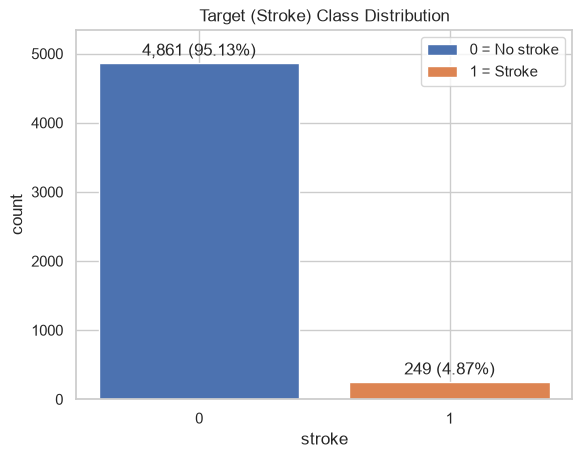

In [5]:
counts = df["stroke"].value_counts().sort_index()
fig, ax = plt.subplots()
bars = ax.bar(counts.index.astype(str), counts.values, color=sns.color_palette()[:2])
ax.bar_label(bars, labels=[f"{n:,} ({n / len(df):.2%})" for n in counts], padding=3)
ax.legend(bars, ["0 = No stroke", "1 = Stroke"])
ax.set_ylim(0, counts.max() * 1.1)
ax.set_xlabel("stroke")
ax.set_ylabel("count")
ax.set_title("Target (Stroke) Class Distribution")
plt.show()

### d) Features Analysis
#### Numeric Features
| Feature | Distribution | Majority range (IQR) | Outliers | Target separation |
|---|---|---|---|---|
| `age` | Roughly symmetric | 25 to 61 | No | Clear |
| `avg_glucose_level` | Right-skewed, small second bump above 200 | 77 to 114 | **No** (after Box-Cox) | Moderate |
| `bmi` | Moderately right-skewed | 23.5 to 33.1 | **Yes** (after Box-Cox) | Weak |

**Handling for `bmi`**
- Outliers: cap at the inclusive range 14.06 to 55.35. 
- Missing values: impute with the median and add a `bmi_missing` flag. The median suits skewed data, and the flag keeps the signal that stroke is more common when BMI is missing (19.9% vs 4.3%). Compute the median on the training set only and apply it to the test set, to avoid data leakage.

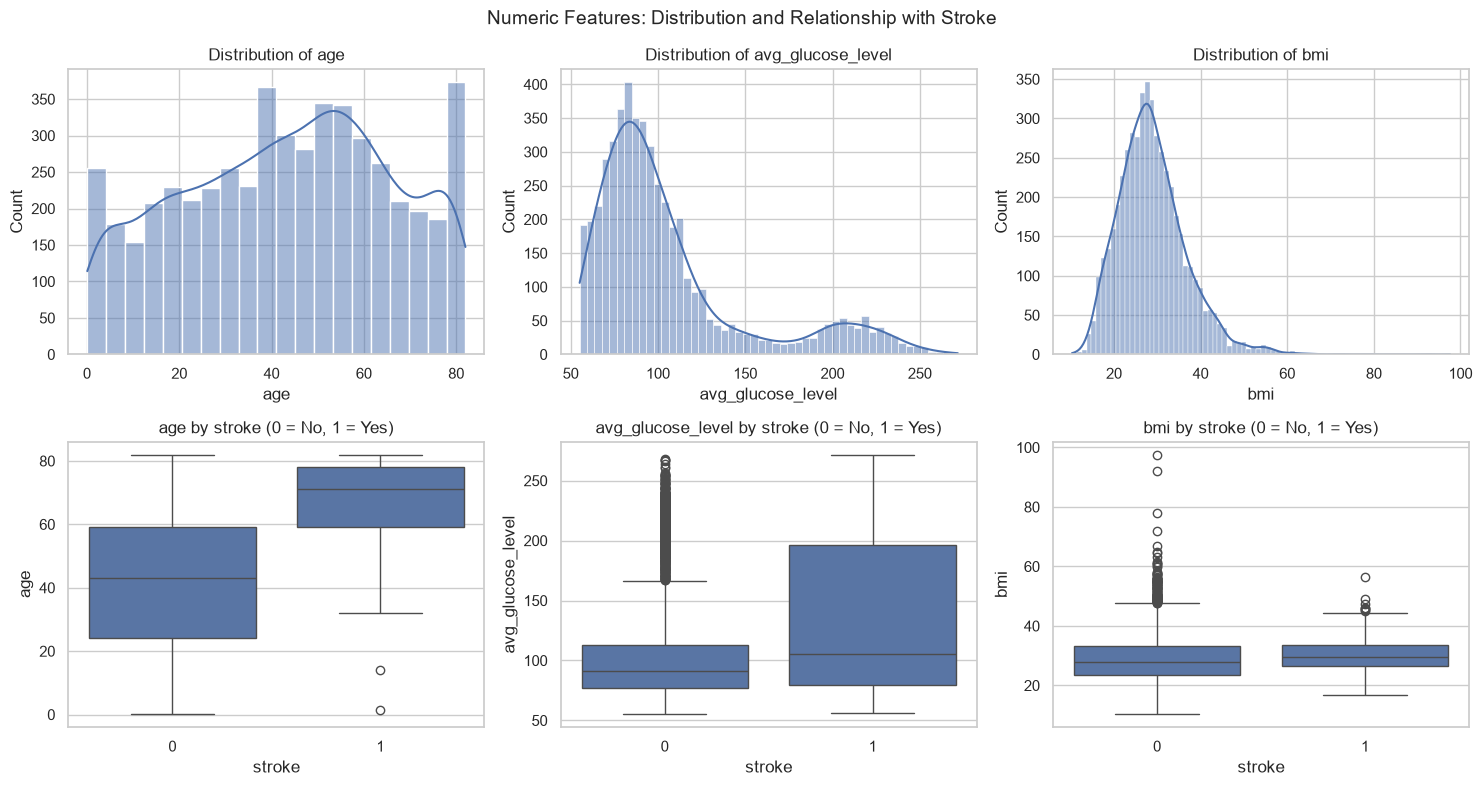

,min,Q1,median,mean,Q3,max,std,skew
age,0.08,25.00,45.00,43.23,61.00,82.00,22.61,-0.14
avg_glucose_level,55.12,77.24,91.88,106.15,114.09,271.74,45.28,1.57
bmi,10.30,23.50,28.10,28.89,33.10,97.60,7.85,1.06


In [6]:
num_cols = ["age", "avg_glucose_level", "bmi"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Distribution of {c}")
    sns.boxplot(data=df, x="stroke", y=c, ax=axes[1, i])
    axes[1, i].set_title(f"{c} by stroke (0 = No, 1 = Yes)")
fig.suptitle("Numeric Features: Distribution and Relationship with Stroke", fontsize=14)
plt.tight_layout()
plt.show()

# Descriptive statistics
summary = pd.DataFrame({
    "min": df[num_cols].min(),
    "Q1": df[num_cols].quantile(0.25),
    "median": df[num_cols].median(),
    "mean": df[num_cols].mean(),
    "Q3": df[num_cols].quantile(0.75),
    "max": df[num_cols].max(),
    "std": df[num_cols].std(),
    "skew": df[num_cols].skew(),
}).round(2)
summary

In [7]:
skewed_cols = ["avg_glucose_level", "bmi"]

def count_iqr_outliers(s):
    """Count values outside 1.5*IQR of the quartiles."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

# Outliers on the raw values (1.5*IQR rule)
raw = pd.Series({c: count_iqr_outliers(df[c].dropna()) for c in num_cols})

# Same rule on Box-Cox transformed values for the skewed columns
boxcox = {}
for c in skewed_cols:
    x = df[c].dropna()
    boxcox[c] = count_iqr_outliers(pd.Series(stats.boxcox(x)[0], index=x.index))
boxcox = pd.Series(boxcox).reindex(num_cols)

n = df[num_cols].count()
outlier_summary = pd.DataFrame({
    "outliers": raw,
    "outliers_pct": (raw / n * 100).round(2),
    "outliers_boxcox": boxcox,
    "outliers_boxcox_pct": (boxcox / n * 100).round(2),
})
outlier_summary

,outliers,outliers_pct,outliers_boxcox,outliers_boxcox_pct
age,0,0.00,NaN,NaN
avg_glucose_level,627,12.27,0.0,0.00
bmi,110,2.24,48.0,0.98


In [8]:
# bmi: range to keep for outlier removal, in original units (both bounds inclusive)
bmi = df["bmi"].dropna()
bmi_bc, lam = stats.boxcox(bmi)
q1_bc, q3_bc = np.percentile(bmi_bc, [25, 75])
iqr_bc = q3_bc - q1_bc
bmi_min = inv_boxcox(q1_bc - 1.5 * iqr_bc, lam)
bmi_max = inv_boxcox(q3_bc + 1.5 * iqr_bc, lam)
print(f"bmi (Box-Cox) keep range (inclusive): {bmi_min:.2f} <= bmi <= {bmi_max:.2f}")
print(f"Below min: {(bmi < bmi_min).sum()}, above max: {(bmi > bmi_max).sum()}")

bmi (Box-Cox) keep range (inclusive): 14.06 <= bmi <= 55.35
Below min: 17, above max: 31


#### Categorical Features

**Handling**
- `gender`: drop the single row with `gender = Other`. One sample is too few to learn from.

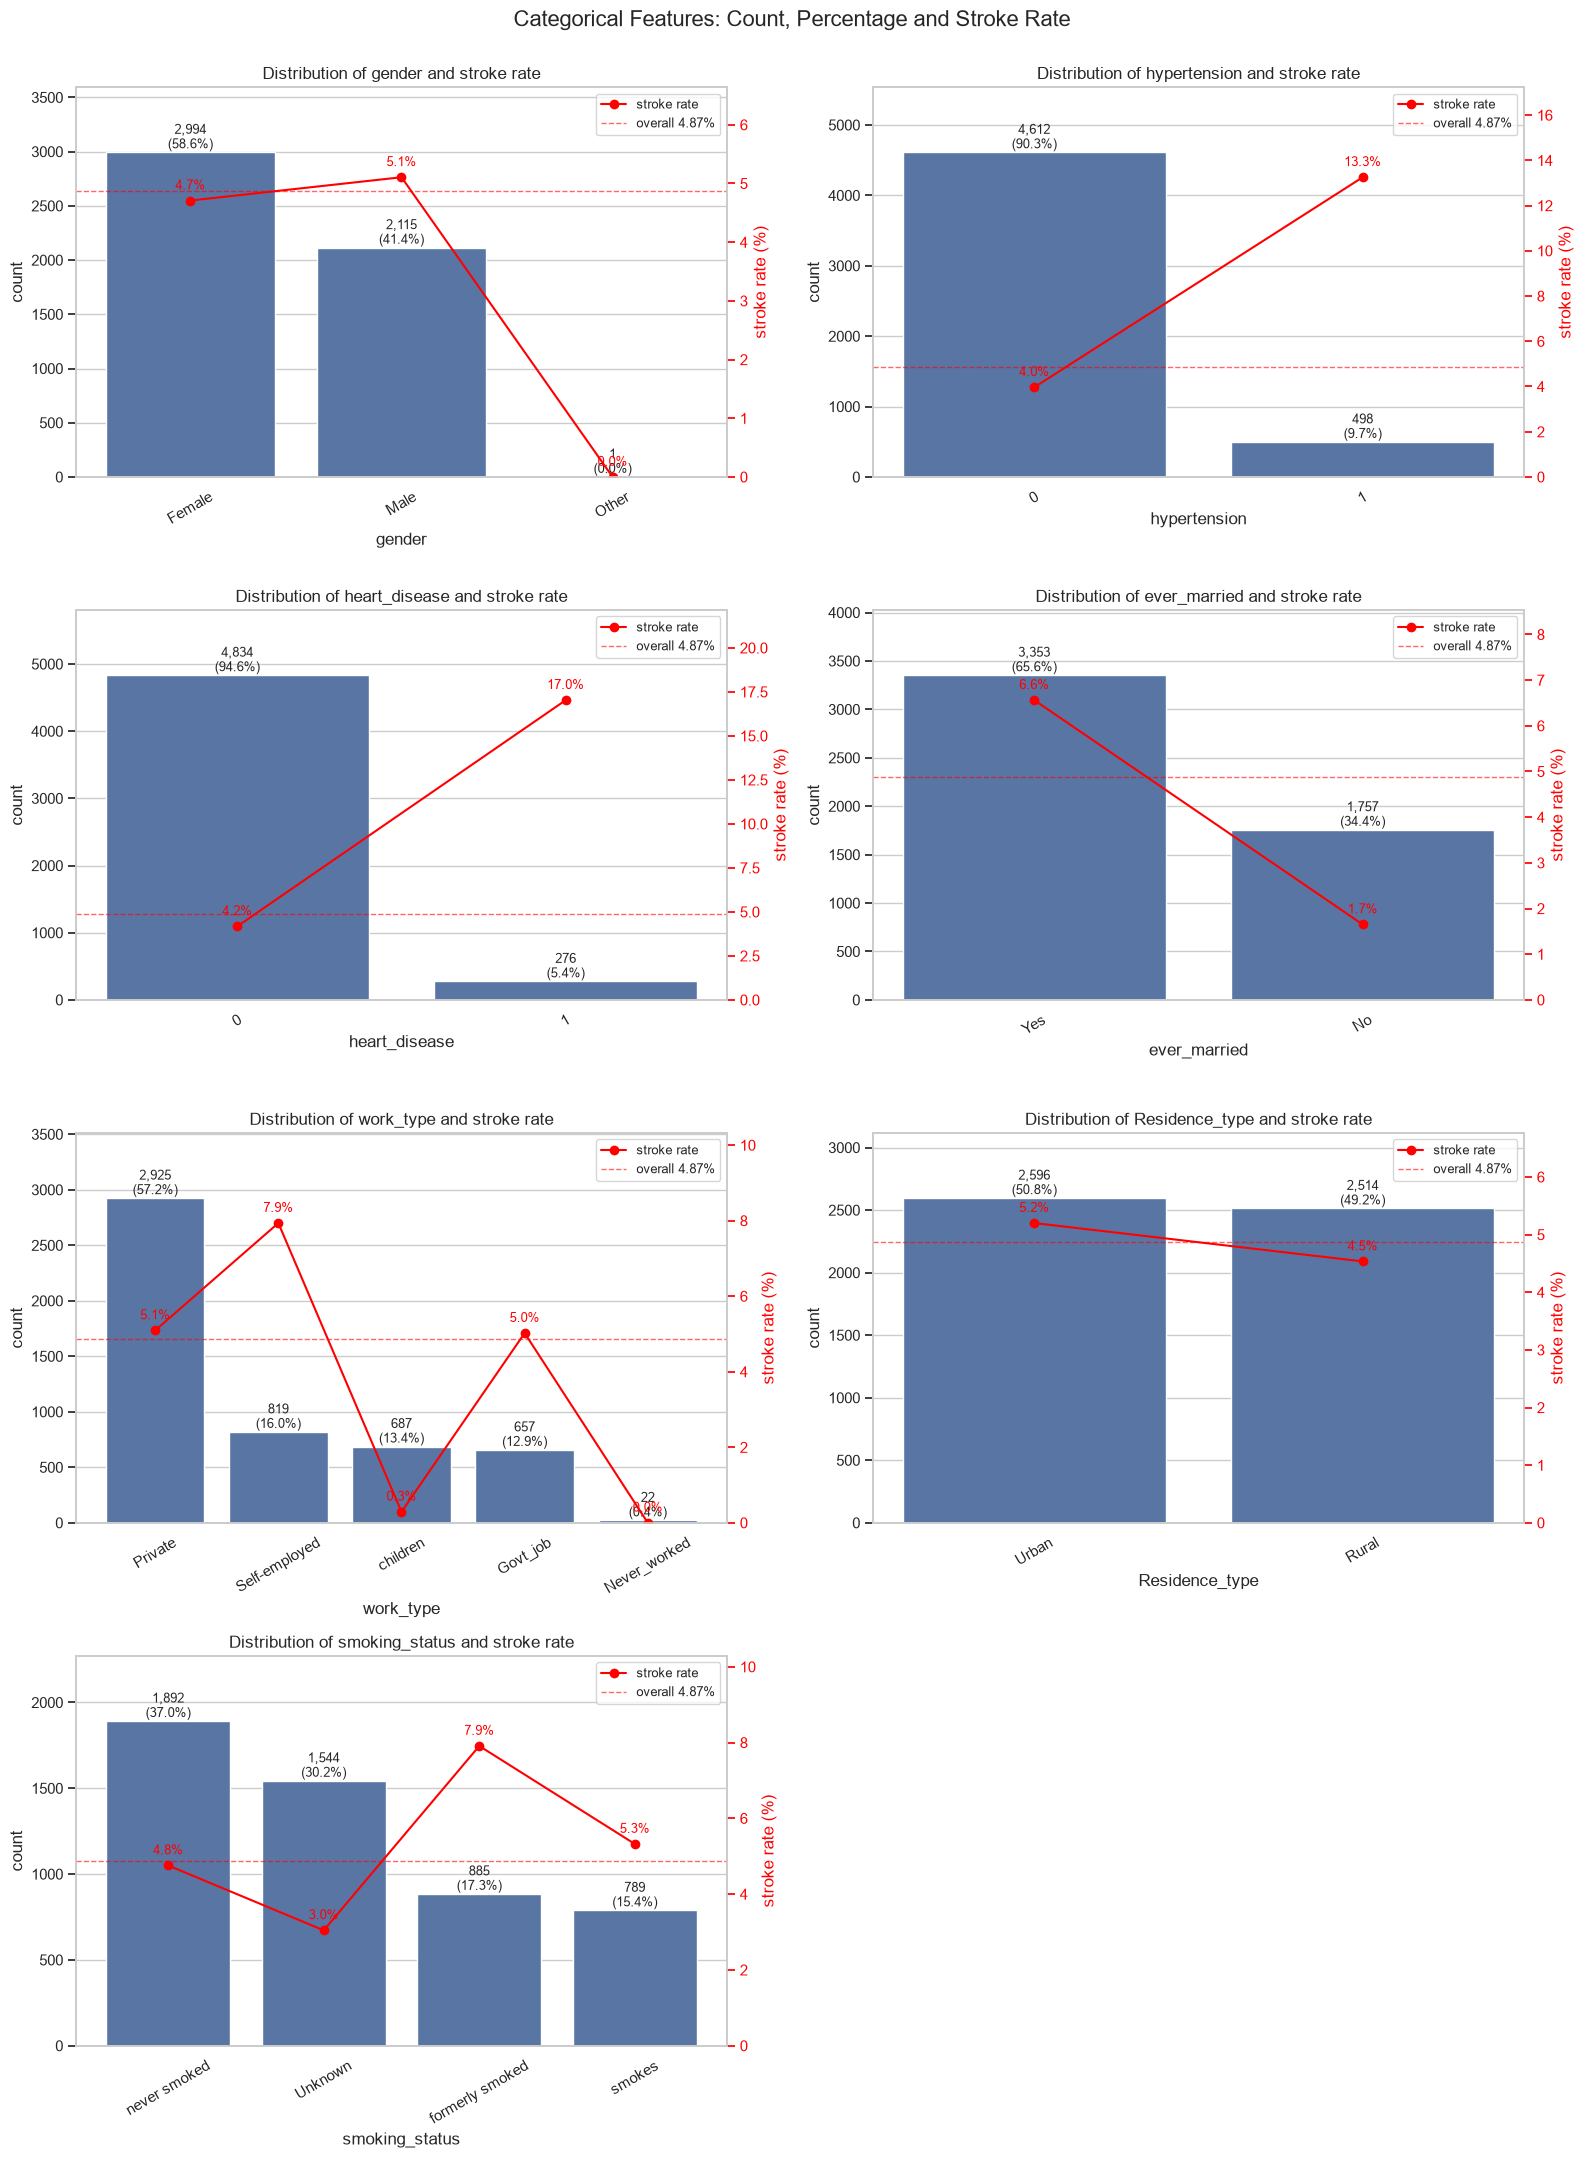

In [9]:
cat_cols = ["gender", "hypertension", "heart_disease", "ever_married",
            "work_type", "Residence_type", "smoking_status"]

overall_rate = df["stroke"].mean() * 100
fig, axes = plt.subplots(4, 2, figsize=(16, 22))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax)
    counts = ax.containers[0].datavalues
    ax.bar_label(ax.containers[0], labels=[f"{n:,.0f}\n({n / len(df):.1%})" for n in counts], fontsize=9)
    ax.set_ylim(0, counts.max() * 1.2)
    ax.set_ylabel("count")
    ax.set_title(f"Distribution of {c} and stroke rate")
    ax.tick_params(axis="x", rotation=30)

    # Stroke rate per category on a secondary axis
    rate = (df.groupby(c)["stroke"].mean() * 100).reindex(order)
    ax2 = ax.twinx()
    ax2.plot(range(len(order)), rate.values, color="red", marker="o", label="stroke rate")
    for x, r in enumerate(rate.values):
        ax2.annotate(f"{r:.1f}%", (x, r), textcoords="offset points", xytext=(0, 8),
                     ha="center", color="red", fontsize=9)
    ax2.axhline(overall_rate, color="red", ls="--", lw=1, alpha=0.6, label=f"overall {overall_rate:.2f}%")
    ax2.set_ylim(0, max(rate.max(), overall_rate) * 1.3)
    ax2.set_ylabel("stroke rate (%)", color="red")
    ax2.tick_params(axis="y", colors="red")
    ax2.grid(False)
    ax2.legend(loc="upper right", fontsize=9)
axes.ravel()[-1].axis("off")
fig.suptitle("Categorical Features: Count, Percentage and Stroke Rate", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

### e) Correlation Analysis

`work_type`, `smoking_status` and `gender` are encoded with their stroke rate (bad rate), so their correlations are meaningful. Binary features use 0/1 codes.

**Key insights**
1. **Overall correlation with stroke:** weak for all features (all ≤ 0.25). This is expected because stroke is rare (4.87%), so low values do not mean the features are useless.
2. **Features that matter most:** `age` (0.25), followed by `hypertension`, `heart_disease`, `avg_glucose_level` (0.13 each) and `ever_married` (0.11).
3. **Features that matter least:** `gender` (0.01), `Residence_type` (0.02) and `bmi` (0.04).
4. **Highly correlated input pairs:** `age`–`ever_married` (0.68), `age`–`work_type` (0.66) and `ever_married`–`work_type` (0.53). All are below 0.7, so multicollinearity is not severe and no handling is needed.

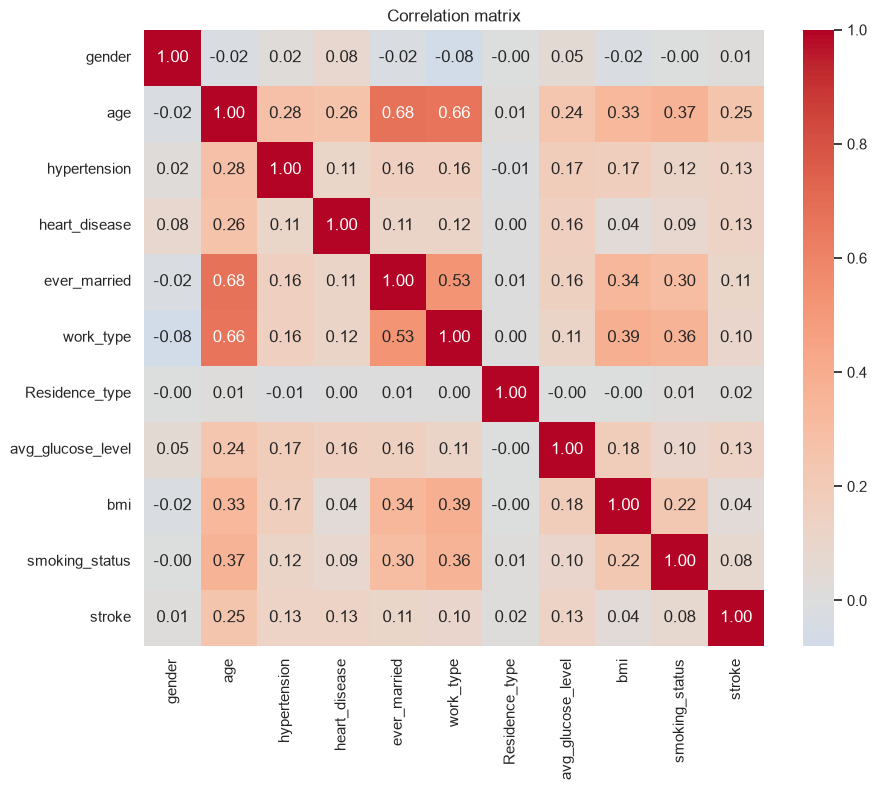

In [10]:
enc = df.drop(columns="id").copy()

# Binary categoricals: 0/1 codes
for c in ["ever_married", "Residence_type"]:
    enc[c] = enc[c].astype("category").cat.codes

# Nominal categoricals: replace each category with its stroke rate (bad rate)
for c in ["gender", "work_type", "smoking_status"]:
    enc[c] = enc[c].map(df.groupby(c)["stroke"].mean())

plt.figure(figsize=(10, 8))
sns.heatmap(enc.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

### f) Data handling and train/test export

| Step | Handling | Reason |
|---|---|---|
| 1 | Drop the single `gender = Other` row | One sample is too few to learn from |
| 2 | Add `bmi_missing` flag | Stroke rate is much higher when `bmi` is missing |
| 3 | Cap `bmi` at (inclusive, 14.06 to 55.35) | Limits extreme values while keeping all rows |
| 4 | Stratified 80/20 train/test split | Keeps the ~4.9% stroke rate in both sets |
| 5 | Impute missing `bmi` with the median | Robust to skew |

Step 5 is computed on the **train set only** and applied to the test set, to avoid data leakage.

In [11]:
# 1. Drop the single gender = Other row (id is kept for tracing, not as a feature)
clean = df[df["gender"] != "Other"].reset_index(drop=True)

# 2. Flag missing bmi before imputing
clean["bmi_missing"] = clean["bmi"].isna().astype(int)

# 3. Cap bmi at the Box-Cox IQR bounds from section d) (inclusive)
clean["bmi"] = clean["bmi"].clip(bmi_min, bmi_max)

# 4. Stratified train/test split (80/20)
train, test = train_test_split(clean, test_size=0.2, stratify=clean["stroke"], random_state=42)
train, test = train.copy(), test.copy()

# 5. Impute missing bmi with the train median
bmi_median = train["bmi"].median()
for d in (train, test):
    d["bmi"] = d["bmi"].fillna(bmi_median)

print(f"bmi cap range: {bmi_min:.2f} to {bmi_max:.2f}, train median: {bmi_median:.2f}")
print(f"Train: {train.shape}, stroke rate {train['stroke'].mean():.2%}")
print(f"Test:  {test.shape}, stroke rate {test['stroke'].mean():.2%}")
print("Missing values left:", train.isna().sum().sum() + test.isna().sum().sum())

# Export
train.to_csv("data/train.csv", index=False)
test.to_csv("data/test.csv", index=False)

bmi cap range: 14.06 to 55.35, train median: 28.10
Train: (4087, 13), stroke rate 4.87%
Test:  (1022, 13), stroke rate 4.89%
Missing values left: 0
